#Introduzione Bank-Marketing

##Obbiettivi
Questo notebook esplora il dataset "Bank Marketing" con lo scopo di costruire e confrontare due modelli di classificazione. L'obiettivo è predire se un cliente di un istituto bancario portoghese aderirà ("yes") o meno ("no") a una campagna di marketing per la sottoscrizione di un deposito a termine

##Dataset
Il dataset è stato ottenuto dal UCI Machine Learning Repository e reso disponibile su Kaggle. Contiene informazioni sui clienti, quali dati anagrafici e finanziari, e dettagli sui contatti passati e presenti della campagna di marketing. Si tratta di un classico problema di classificazione binaria in un contesto reale.


## Contenuto
1. Data Exploration
2. Data Analysis
3. Feature Engineering
4. Decision Tree
5. SVM
6. Confronto risultati

#Parte Iniziale

## Import delle Librerie necessarie


In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
from math import pi
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import GridSearchCV

from sklearn.dummy import DummyClassifier

##Import Dataset

In [ ]:
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "janiobachmann/bank-marketing-dataset",
  "bank.csv",
)

Using Colab cache for faster access to the 'bank-marketing-dataset' dataset.


##Data Exploration

###Ispezione Iniziale

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [ ]:
df.shape

(11162, 17)

In [ ]:
df.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,"11,162.0000","11,162.0000","11,162.0000","11,162.0000","11,162.0000","11,162.0000","11,162.0000"
mean,41.2319,"1,528.5385",15.6580,371.9938,2.5084,51.3304,0.8326
std,11.9134,"3,225.4133",8.4207,347.1284,2.7221,108.7583,2.2920
min,18.0000,"-6,847.0000",1.0000,2.0000,1.0000,-1.0000,0.0000
25%,32.0000,122.0000,8.0000,138.0000,1.0000,-1.0000,0.0000
50%,39.0000,550.0000,15.0000,255.0000,2.0000,-1.0000,0.0000
75%,49.0000,"1,708.0000",22.0000,496.0000,3.0000,20.7500,1.0000
max,95.0000,"81,204.0000",31.0000,"3,881.0000",63.0000,854.0000,58.0000


In [ ]:
print("Righe Duplicate:", df.duplicated().sum())

Righe Duplicate: 0


###Distribuzione Target

,count
deposit,
no,5873
yes,5289


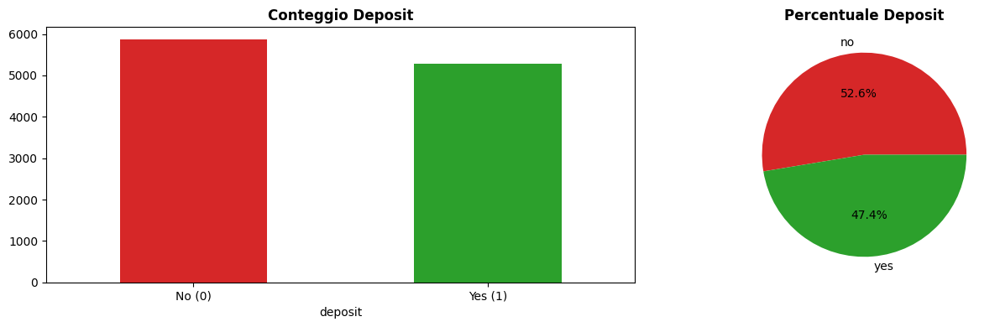

In [ ]:
#conteggio numerico
counts = df['deposit'].value_counts()
display(df["deposit"].value_counts())

#istogramma
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts.plot(kind='bar', ax=axes[0], color=['#d62728', '#2ca02c'])
axes[0].set_title('Conteggio Deposit', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['No (0)', 'Yes (1)'], rotation=0)

#torta
(counts/len(df)*100).plot(kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['#d62728', '#2ca02c'])
axes[1].set_ylabel('')
axes[1].set_title('Percentuale Deposit', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

###Valori Mancanti

In [ ]:
# NaN reali
na = df.isna().sum().sort_values(ascending=False)
display("Numero di NaN", na[na>0])

# conto i campi con “unknown”
cat_cols = df.select_dtypes(include=["object","category"]).columns
unknown_counts = {c: (df[c].astype(str).eq("unknown")).sum() for c in cat_cols}
unknown_counts = (pd.Series(unknown_counts).sort_values(ascending=False))
display(unknown_counts[unknown_counts>0])

#rimuovo poutcome perchè ha tanti unkown
df= df.drop('poutcome', axis=1)

'Numero di NaN'

,0


,0
poutcome,8326
contact,2346
education,497
job,70


###Distribuzione attributi rispetto al target

####Attributi con > 2 label

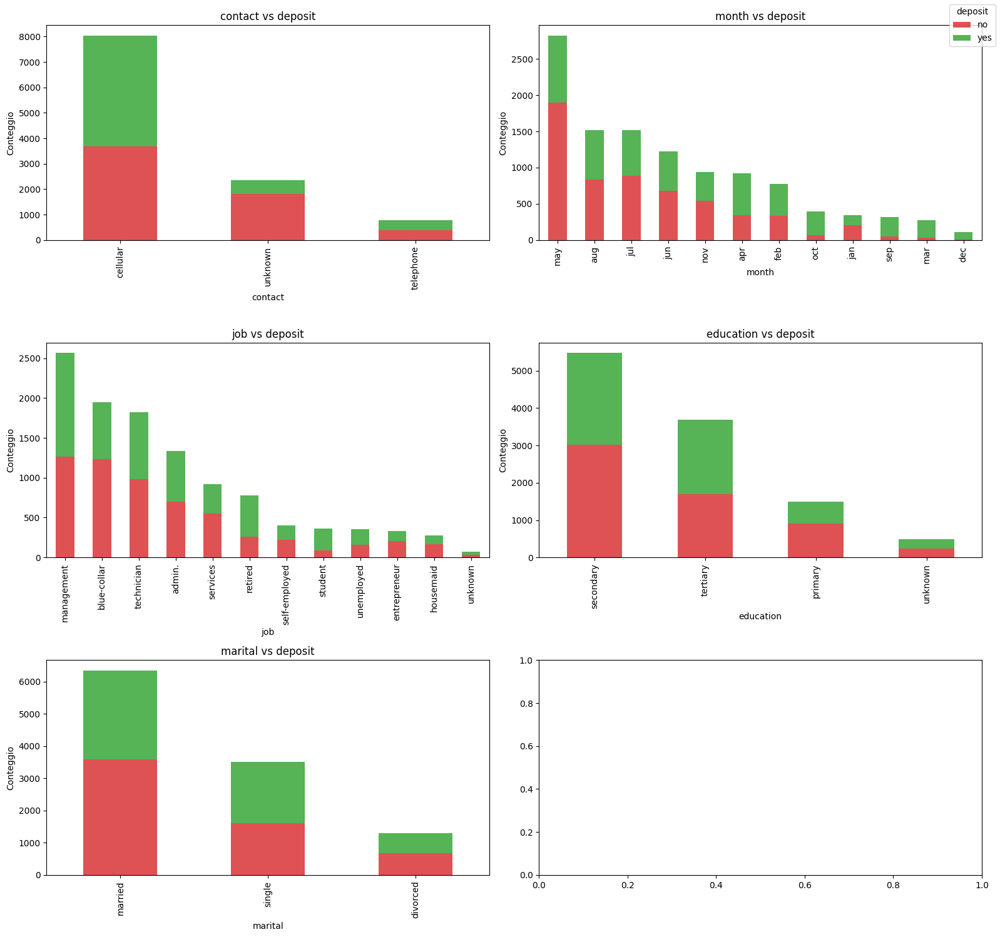

In [ ]:
# seleziono le feature
features = ["contact", "month", "job", "education", "marital"]

# creo i grafici delle feature distribuiti per variabile target "deposit"
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    tab = pd.crosstab(df[feature], df["deposit"])
    tab = tab.loc[tab.sum(axis=1).sort_values(ascending=False).index]

    tab.plot(kind="bar", stacked=True, color=["#d62728", "#2ca02c"],alpha=0.8, ax=ax, legend=False)
    ax.set_title(f"{feature} vs deposit")
    ax.set_xlabel(feature)
    ax.set_ylabel("Conteggio")
    ax.tick_params(axis="x", labelrotation=90)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="deposit", loc="upper right")

plt.tight_layout()
plt.show()

####Attributi binari

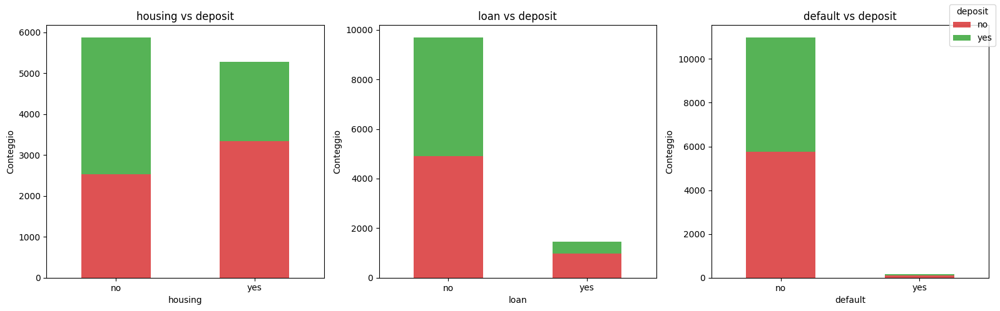

In [ ]:
# seleziono le feature
features = ["housing", "loan", "default"]

# creo i grafici delle feature distribuiti per variabile target "deposit"
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    tab = pd.crosstab(df[feature], df["deposit"])
    tab = tab.loc[tab.sum(axis=1).sort_values(ascending=False).index]

    tab.plot(kind="bar", stacked=True, color=["#d62728", "#2ca02c"],
             alpha=0.8, ax=ax, legend=False,)
    ax.set_title(f"{feature} vs deposit")
    ax.set_xlabel(feature)
    ax.set_ylabel("Conteggio")
    ax.tick_params(axis="x", labelrotation=0)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="deposit", loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
#rimuovo default perchè dal grafico vedo che non serve
df= df.drop('default', axis=1)

####Attributi Numerici

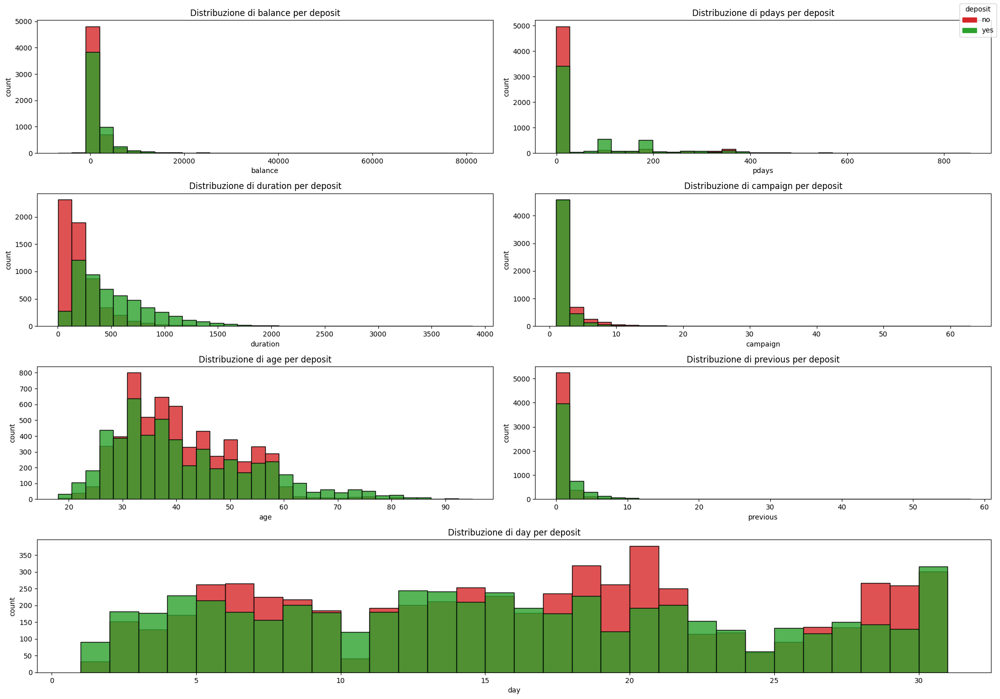

In [ ]:
# seleziono le feature
num_cols = ['balance', 'pdays', 'duration', 'campaign', 'age', 'previous', 'day']

# creo i grafici delle feature distribuiti per variabile target "deposit"
fig, axs = plt.subplots(4, 2, figsize=(20, 14))
gs = axs[0, 0].get_gridspec()

# per visualizzare l'ultimo grafico intero sulla riga
for ax in axs[3, :]:
    ax.remove()
ax_big = fig.add_subplot(gs[3, :])
axes = axs[:3, :].flatten().tolist() + [ax_big]

for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=df, x=col, hue="deposit",
        bins=30, alpha=0.8,
        palette={"no":"#d62728", "yes":"#2ca02c"},
        legend=False,
        multiple="layer",
        ax=ax
    )
    ax.set_title(f"Distribuzione di {col} per deposit")
    ax.set_xlabel(col)
    ax.set_ylabel("count")
    ax.grid(False)

handles = [Patch(color="#d62728", label="no"),
           Patch(color="#2ca02c", label="yes")]
fig.legend(handles=handles, title="deposit", loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
# guardo le feature che hanno una distribuzione più alta tutta in un unico punto
display(df["pdays"].value_counts().head(3))
display(df["campaign"].value_counts().head(3))
display(df["previous"].value_counts().head(3))
display(df["balance"].value_counts().head(3))

,count
pdays,
-1,8324
92,106
182,89


,count
campaign,
1,4798
2,3028
3,1321


,count
previous,
0,8324
1,887
2,693


,count
balance,
0,774
1,39
3,35


## Train/Test Split

In [ ]:
# Effettuiamo lo split PRIMA del feature engineering per evitare data leakage.
# Prima convertiamo il target per lo split
y = (df['deposit'] == 'yes').astype(int)
X = df.drop('deposit', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"\nDistribuzione target nel training: \n", y_train.value_counts())
print(f"\nDistribuzione target nel test: \n", y_test.value_counts())


Training set: (8929, 14)
Test set: (2233, 14)

Distribuzione target nel training: 
 deposit
0    4698
1    4231
Name: count, dtype: int64

Distribuzione target nel test: 
 deposit
0    1175
1    1058
Name: count, dtype: int64


## Feature Engeeniring

### 1 Engineering in comune

In [ ]:
def engineering_comune(df, rare_jobs, dummy_cols_dict):
  df_proc = df.copy()

  # Job: rare -> other + one-hot (matching colonne training)
  df_proc['job'] = df_proc['job'].replace(rare_jobs, 'other')
  job_dummies = pd.get_dummies(df_proc['job'], prefix='job')
  job_dummy_cols = dummy_cols_dict['job']
  for col in job_dummy_cols:
      if col not in job_dummies.columns:
          job_dummies[col] = 0
  job_dummies = job_dummies[job_dummy_cols]
  df_proc = pd.concat([df_proc, job_dummies], axis=1)

  # One-hot encoding per marital, education, contact, month e poutcome
  for col, prefix in [('marital', 'marital'), ('education', 'education'),
                        ('contact', 'contact'), ('month', 'month')]:
      dummies = pd.get_dummies(df_proc[col], prefix=prefix)
      dummy_cols = dummy_cols_dict[prefix]
      for dc in dummy_cols:
          if dc not in dummies.columns:
              dummies[dc] = 0
      dummies = dummies[dummy_cols]
      df_proc = pd.concat([df_proc, dummies], axis=1)

  # Conversioni binarie per housing e loan
  for col in ['housing', 'loan']:
      df_proc[col] = (df_proc[col] == 'yes').astype(bool)

  # Feature derivate
  df_proc['pdays_is_negative'] = (df_proc['pdays'] == -1).astype(bool)
  df_proc['previous_is_0'] = (df_proc['previous'] == 0).astype(bool)
  df_proc['total_contacts'] = df_proc['campaign'] + df_proc['previous']

  return df_proc

# Calcolo parametri sul training
job_counts = X_train['job'].value_counts()
rare_jobs = job_counts[job_counts < len(X_train) * 0.05].index.tolist()

# Calcolo colonne dummy (dopo replace per job)
dummy_cols_dict = {}
X_temp = X_train.copy()
# sostituisce i rare jobs con other
X_temp['job'] = X_temp['job'].replace(rare_jobs, 'other')
for col, prefix in [('job', 'job'), ('marital', 'marital'), ('education', 'education'),
                     ('contact', 'contact'), ('month', 'month')]:
    dummy_cols_dict[prefix] = pd.get_dummies(X_temp[col], prefix=prefix).columns.tolist()

# Applicazione trasformazioni su train e su test comuni
X_train_common = engineering_comune(X_train, rare_jobs, dummy_cols_dict)
X_test_common = engineering_comune(X_test, rare_jobs, dummy_cols_dict)



### 2 Engineering Decision tree

In [ ]:
def engineering_dt(df, age_bounds, age_bins, balance_bounds, tc_bins):
    df_proc = df.copy()

    #faccio clipping e binning di age con le fasce passate per parametro
    df_proc['age'] = df_proc['age'].clip(lower=age_bounds[0], upper=age_bounds[1])
    df_proc['age_binned'] = pd.cut(df_proc['age'], bins=age_bins, labels=False, include_lowest=True)

    #faccio binning di balance con le fasce passate per parametro
    df_proc['balance'] = df_proc['balance'].clip(lower=balance_bounds[0], upper=balance_bounds[1])

    df_proc['total_contacts'] = df_proc['total_contacts'].clip(lower=tc_bins[0], upper=tc_bins[-1])
    df_proc['total_contacts_binned'] = pd.cut(df_proc['total_contacts'], bins=tc_bins, labels=False, include_lowest=True)

    return df_proc


#Trovo minimi e massimi nuovi per clipping age utilizzando metodo IQR e poi creo le fasce da utilizzare per binnare
Q1_age, Q3_age = X_train_common['age'].quantile([0.25, 0.75])
IQR_age = Q3_age - Q1_age
age_bounds_dt = (max(18, Q1_age - 1.5*IQR_age), min(100, Q3_age + 1.5*IQR_age))
X_temp = X_train_common.copy()
X_temp['age'] = X_temp['age'].clip(lower=age_bounds_dt[0], upper=age_bounds_dt[1])
age_cut = pd.cut(X_temp['age'], bins=5, retbins=True, duplicates='drop')
age_bins_dt = age_cut[1]

#Trovo minimi e massimi nuovi per clipping balance utilizzando metodo percentili fissi
balance_bounds_dt = tuple(X_train_common['balance'].quantile([0.05, 0.95]))

#Creo le fasce per total_contact da utilizzare per binning
tc_cut = pd.cut(X_train_common['total_contacts'], bins=5, retbins=True, duplicates='drop')
tc_bins_dt = tc_cut[1]

# Applicazione trasformazioni
X_train_dt = engineering_dt(X_train_common, age_bounds_dt, age_bins_dt, balance_bounds_dt, tc_bins_dt)
X_test_dt = engineering_dt(X_test_common, age_bounds_dt, age_bins_dt, balance_bounds_dt, tc_bins_dt)


### 3 Engineering SVM

In [ ]:
def engineering_svm(df, age_bounds, balance_bounds, tc_bounds,pdays_upper, scaler):
    df_proc = df.copy()

    # Clipping delle variabili continue
    df_proc['age'] = df_proc['age'].clip(lower=age_bounds[0], upper=age_bounds[1])
    df_proc['balance'] = df_proc['balance'].clip(lower=balance_bounds[0], upper=balance_bounds[1])
    df_proc['pdays'] = df_proc['pdays'].clip(upper=pdays_upper)

    # Total contacts log
    df_proc['total_contacts'] = df_proc['total_contacts'].clip(lower=tc_bounds[0], upper=tc_bounds[1])
    df_proc['total_contacts_log'] = np.log1p(df_proc['total_contacts'])

    # --- SCALING ---
    X = df_proc.copy()
    X_scaled = X.copy()

    # Lista di TUTTE le colonne numeriche continue da scalare
    numeric_cols_to_scale = ['age', 'balance', 'day', 'total_contacts_log', 'pdays']

    # Applica lo scaler
    cols_present = [c for c in numeric_cols_to_scale if c in X_scaled.columns]
    X_scaled[cols_present] = scaler.transform(X[cols_present])

    return X_scaled

# 1. Calcolo Bounds
Q1_age, Q3_age = X_train_common['age'].quantile([0.25, 0.75])
IQR_age = Q3_age - Q1_age
age_bounds_svm = (max(18, Q1_age - 1.5*IQR_age), min(100, Q3_age + 1.5*IQR_age))

balance_bounds_svm = tuple(X_train_common['balance'].quantile([0.05, 0.95]))
tc_bounds_svm = tuple(X_train_common['total_contacts'].quantile([0.05, 0.95]))
pdays_upper = X_train_common[X_train_common['pdays'] > 0]['pdays'].quantile(0.99)

# 2. Setup Scaler
scaler_svm = StandardScaler()
X_temp_scaler = X_train_common.copy()

# Applica clipping preliminare su X_temp_scaler per fittare lo scaler sui dati 'puliti'
X_temp_scaler['age'] = X_temp_scaler['age'].clip(lower=age_bounds_svm[0], upper=age_bounds_svm[1])
X_temp_scaler['balance'] = X_temp_scaler['balance'].clip(lower=balance_bounds_svm[0], upper=balance_bounds_svm[1])
X_temp_scaler['total_contacts'] = X_temp_scaler['total_contacts'].clip(lower=tc_bounds_svm[0], upper=tc_bounds_svm[1])
X_temp_scaler['total_contacts_log'] = np.log1p(X_temp_scaler['total_contacts'])

# Fit dello Scaler su TUTTE le numeriche continue, inclusa pdays
cols_to_fit = ['age', 'balance', 'day', 'total_contacts_log', 'pdays']
scaler_svm.fit(X_temp_scaler[cols_to_fit])

# 3. Applicazione
X_train_svm = engineering_svm(X_train_common, age_bounds_svm, balance_bounds_svm,
                              tc_bounds_svm, pdays_upper, scaler_svm)

X_test_svm = engineering_svm(X_test_common, age_bounds_svm, balance_bounds_svm,
                             tc_bounds_svm, pdays_upper,  scaler_svm)


In [ ]:
display(X_train_svm.dtypes)

,0
age,float64
job,object
marital,object
education,object
balance,float64
housing,bool
loan,bool
contact,object
day,float64
month,object


### 4 Target

In [ ]:
# creo le Feature target per train e test per entrambi i modelli
y_train_dt = y_train.copy()
y_test_dt = y_test.copy()
y_train_svm = y_train.copy()
y_test_svm = y_test.copy()

### 5 Feature Reduction

#### Feature Selection

In [ ]:
#Applico feauture selection rimuovendo le colonne che non mi servono dai train di decision tree e svm
X_train_dt.drop(columns=['contact', 'previous', 'campaign','marital', 'education', 'contact', 'month', 'job', 'duration', 'total_contacts', 'age'], inplace=True)
X_test_dt.drop(columns=['contact', 'previous', 'campaign', 'marital', 'education', 'contact', 'month', 'job', 'duration', 'total_contacts', 'age'], inplace=True)
X_train_svm.drop(columns=['contact', 'previous','campaign', 'marital', 'education', 'contact', 'month', 'job', 'duration','total_contacts'], inplace=True)

In [ ]:
print(f"Decision Tree: {len(X_train_dt.columns)} features | Train: {X_train_dt.shape} | Test: {X_test_dt.shape}")
print(f"  Colonne match: {set(X_train_dt.columns) == set(X_test_dt.columns)} | NaN: train={X_train_dt.isna().sum().sum()}, test={X_test_dt.isna().sum().sum()}")
print(f"\nSVM: {len(X_train_svm.columns.tolist())} features | Train: {X_train_svm.shape} | Test: {X_test_svm.shape}")
print(f"  Colonne match: {set(X_train_svm.columns) == set(X_test_svm.columns)} | NaN: train={X_train_svm.isna().sum().sum()}, test={X_test_svm.isna().sum().sum()}")

Decision Tree: 38 features | Train: (8929, 38) | Test: (2233, 38)
  Colonne match: True | NaN: train=0, test=0

SVM: 38 features | Train: (8929, 38) | Test: (2233, 47)
  Colonne match: False | NaN: train=0, test=0


#### Feature Extraction

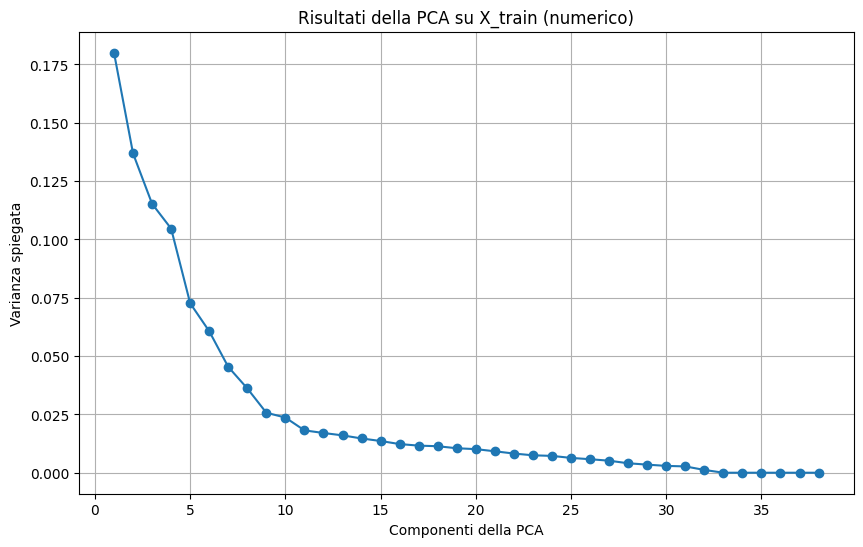

In [ ]:
#Eseguo pca su train del svm
pca = PCA().fit(X_train_svm)

# Crea un grafico della varianza spiegata per ogni componente
plt.figure(figsize=(10, 6))
plt.plot(range(1, pca.n_components_ + 1), pca.explained_variance_ratio_, marker='o')
plt.xlabel('Componenti della PCA')
plt.ylabel('Varianza spiegata')
plt.title("Risultati della PCA su X_train (numerico)")
plt.grid(True)
plt.show()

In [ ]:
#Guardo quanti componenti mi servono per rappresentare 90% di varianza
print(pca.explained_variance_ratio_)

[1.80023444e-01 1.36851664e-01 1.15269527e-01 1.04633215e-01
 7.26325648e-02 6.06595148e-02 4.53574569e-02 3.61376029e-02
 2.57119980e-02 2.36482957e-02 1.81565559e-02 1.70321016e-02
 1.60117806e-02 1.46866567e-02 1.35938756e-02 1.22818243e-02
 1.16147397e-02 1.13544256e-02 1.04928648e-02 1.01120774e-02
 9.18856129e-03 8.22234774e-03 7.46698625e-03 7.21482786e-03
 6.34798240e-03 5.79044049e-03 5.15189612e-03 4.05354438e-03
 3.46766948e-03 2.92947008e-03 2.70721471e-03 1.19687447e-03
 1.43304608e-17 1.37776812e-17 8.82021142e-18 0.00000000e+00
 0.00000000e+00 0.00000000e+00]


In [ ]:
# Applica la PCA per ridurre la dimensionalità dei dati
pca = PCA(n_components=5).fit(X_train_svm)
pca_data = pca.transform(X_train_svm)

# Quantifichiamo  la percentuale di varianza spiegata da ciascuno delle componenti.
print(pca.explained_variance_ratio_)

[0.18002344 0.13685166 0.11526953 0.10463321 0.07263256]


In [ ]:
#Verifichiamo il coefficienti degli autovalori
eigenvalues = pca.explained_variance_
n_samples = X_train_svm.shape[0]
cov_matrix = np.dot(X_train_svm.T, X_train_svm) / n_samples
for eigenvalue, eigenvector in zip(eigenvalues, pca.components_):
    #print(np.dot(eigenvector.T, np.dot(cov_matrix, eigenvector)))
    print(eigenvalue)

1.6262596048559415
1.2362630498043483
1.0412986812283107
0.9452145023438018
0.6561334637224466


### 6 Stampa Feature

In [ ]:
def format_features_list(features, items_per_line=10):
    return "\n    - ".join([", ".join(features[i:i + items_per_line]) for i in range(0, len(features), items_per_line)])

print(f"\nFeatures Decision Tree")
print(f"  Numero totale di feature: {len(X_train_dt.columns)}")
print(f"  Shape Training Set: {X_train_dt.shape}")
print(f"  Shape Test Set: {X_test_dt.shape}")
print(f"  Coerenza delle colonne tra Training e Test Set: {set(X_train_dt.columns) == set(X_test_dt.columns)}")
print(f"  Valori mancanti (NaN) nel Training Set: {X_train_dt.isna().sum().sum()}")
print(f"  Valori mancanti (NaN) nel Test Set: {X_test_dt.isna().sum().sum()}")
print(f"  Train Features selezionate:\n    - {format_features_list(X_train_dt.columns.tolist())}")

print(f"\nFeatures Modello SVM")
print(f"  Numero totale di feature: {len(X_train_svm.columns.tolist())}")
print(f"  Shape Training Set: {X_train_svm.shape}")
print(f"  Shape Test Set: {X_test_svm.shape}")
print(f"  Coerenza delle colonne tra Training e Test Set: {set(X_train_svm.columns) == set(X_test_svm.columns)}")
print(f"  Valori mancanti (NaN) nel Training Set: {X_train_svm.isna().sum().sum()}")
print(f"  Valori mancanti (NaN) nel Test Set: {X_test_svm.isna().sum().sum()}")
print(f"  Train Features selezionate:\n    - {format_features_list(X_train_svm.columns.tolist())}")


Features Decision Tree
  Numero totale di feature: 38
  Shape Training Set: (8929, 38)
  Shape Test Set: (2233, 38)
  Coerenza delle colonne tra Training e Test Set: True
  Valori mancanti (NaN) nel Training Set: 0
  Valori mancanti (NaN) nel Test Set: 0
  Train Features selezionate:
    - balance, housing, loan, day, pdays, job_admin., job_blue-collar, job_management, job_other, job_retired
    - job_services, job_technician, marital_divorced, marital_married, marital_single, education_primary, education_secondary, education_tertiary, education_unknown, contact_cellular
    - contact_telephone, contact_unknown, month_apr, month_aug, month_dec, month_feb, month_jan, month_jul, month_jun, month_mar
    - month_may, month_nov, month_oct, month_sep, pdays_is_negative, previous_is_0, age_binned, total_contacts_binned

Features Modello SVM
  Numero totale di feature: 38
  Shape Training Set: (8929, 38)
  Shape Test Set: (2233, 47)
  Coerenza delle colonne tra Training e Test Set: False
  V

#Dummy Models

## 1 Classe target dominante


In [ ]:
# Questo modello predice sempre 1 (SI), perché è la classe dominante
dummy_most_frequent = DummyClassifier(strategy="most_frequent")
dummy_most_frequent.fit(X_train, y_train)
y_pred_dummy1 = dummy_most_frequent.predict(X_test)

print(f"\nDUMMY 1: Sempre 'SI'")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy1):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy1):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dummy1):.4f}")


DUMMY 1: Sempre 'SI'
Accuracy:  0.5262
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000


## 2 Variabile Euristica più separata
Se lo contatto via cellular, allora dirà Sì (1). Se lo contatto via unknown o telephone, dirà No (0).

In [ ]:
y_pred_dummy2 = X_test['contact'].apply(lambda x: 1 if x == 'cellular' else 0)

# Metriche
print(f"\nDUMMY 2: Regola euristica (Cellular -> Yes)")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy2):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy2, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy2):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dummy2):.4f}")


DUMMY 2: Regola euristica (Cellular -> Yes)
Accuracy:  0.5871
Precision: 0.5423
Recall:    0.8233
F1-Score:  0.6539


#Modello 1: Decision Tree

## Prima parte: Albero completo (senza pruning)
Addestriamo l'albero decisionale completo e analizziamo le sue prestazioni con tutte le metriche.



### 1 Addestramento albero completo


In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_dt, y_train_dt)

print("Modello addestrato con successo!")
print(f"Profondità albero: {dt.tree_.max_depth}")
print(f"Numero di nodi: {dt.tree_.node_count}")

# Visualizzazione albero completo
fig, ax = plt.subplots(figsize=(300, 150))
plot_tree(dt, feature_names=X_train_dt.columns.tolist(), class_names=['No','Yes'], filled=True, ax=ax, fontsize=8)
plt.title('Decision Tree - Albero Completo (senza pruning)', fontsize=20)
plt.show()

Modello addestrato con successo!
Profondità albero: 39
Numero di nodi: 5015


### 2 Predizioni e metriche

In [ ]:
y_pred_full  = dt.predict(X_test_dt)
y_proba_dt = dt.predict_proba(X_test_dt)[:,1]

metrics_dt = {
    'accuracy': accuracy_score(y_test_dt, y_pred_full ),
    'precision': precision_score(y_test_dt, y_pred_full ),
    'recall': recall_score(y_test_dt, y_pred_full ),
    'f1': f1_score(y_test_dt, y_pred_full )
}
print(metrics_dt)
print("\nClassification report:\n", classification_report(y_test_dt, y_pred_full ))

{'accuracy': 0.6287505597850426, 'precision': 0.6065116279069768, 'recall': 0.6162570888468809, 'f1': 0.6113455227379277}

Classification report:
               precision    recall  f1-score   support

           0       0.65      0.64      0.64      1175
           1       0.61      0.62      0.61      1058

    accuracy                           0.63      2233
   macro avg       0.63      0.63      0.63      2233
weighted avg       0.63      0.63      0.63      2233



### 3 Confusion Matrix

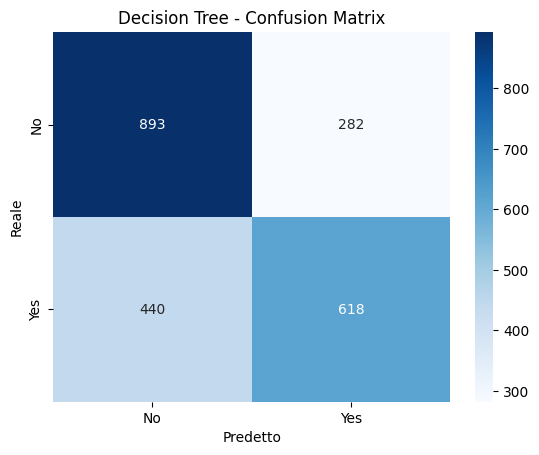

In [ ]:
cm_dt = confusion_matrix(y_test_dt, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predetto')
plt.ylabel('Reale')
plt.show()

## Seconda parte: Pruning fisso e analisi dei cambiamenti
Applichiamo il pruning all'albero in modo fisso a 6 livelli.

###1 Addestramento albero con pruning a 6 livelli


Albero potato addestrato!
Profondità effettiva: 6
Numero di nodi: 123


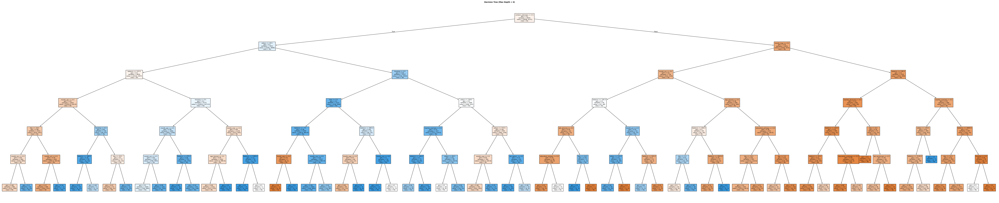

In [ ]:
dt_depth6 = DecisionTreeClassifier(random_state=42, max_depth=6)
dt_depth6.fit(X_train_dt, y_train_dt)

print("\nAlbero potato addestrato!")
print(f"Profondità effettiva: {dt_depth6.tree_.max_depth}")
print(f"Numero di nodi: {dt_depth6.tree_.node_count}")

fig, ax = plt.subplots(figsize=(100, 20))
plot_tree(dt_depth6,
          feature_names=X_train_dt.columns.tolist(),
          class_names=['No', 'Yes'],
          filled=True,
          ax=ax,
          fontsize=8,
          precision=2)

plt.title('Decision Tree (Max Depth = 6)', fontsize=10, fontweight='bold')
plt.show()


### 2 Predizioni e metriche

In [ ]:
y_pred_depth6 = dt_depth6.predict(X_test_dt)

metrics_dt_depth6 = {
    'accuracy': accuracy_score(y_test_dt, y_pred_depth6),
    'precision': precision_score(y_test_dt, y_pred_depth6),
    'recall': recall_score(y_test_dt, y_pred_depth6),
    'f1': f1_score(y_test_dt, y_pred_depth6)
}

print("METRICHE ALBERO DEPTH=6")
print(metrics_dt_depth6)
print("\nClassification report (Depth 6):\n", classification_report(y_test_dt, y_pred_depth6))

METRICHE ALBERO DEPTH=6
{'accuracy': 0.6766681594267802, 'precision': 0.6866666666666666, 'recall': 0.5841209829867675, 'f1': 0.6312563840653729}

Classification report (Depth 6):
               precision    recall  f1-score   support

           0       0.67      0.76      0.71      1175
           1       0.69      0.58      0.63      1058

    accuracy                           0.68      2233
   macro avg       0.68      0.67      0.67      2233
weighted avg       0.68      0.68      0.67      2233



### 3 Confusion Matrix

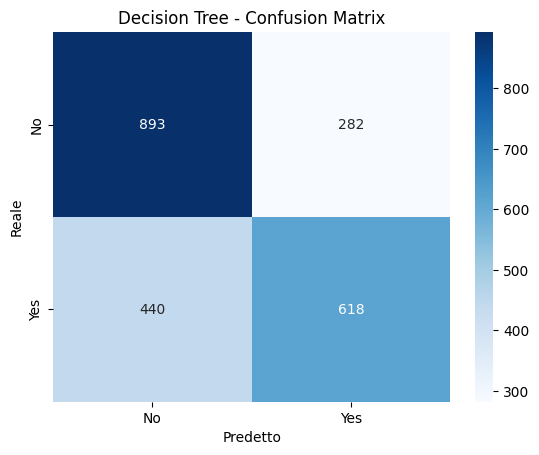

In [ ]:
cm_dt = confusion_matrix(y_test_dt, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predetto')
plt.ylabel('Reale')
plt.show()

## Terza parte: Pruning e analisi dei cambiamenti
Applichiamo il pruning all'albero e confrontiamo i risultati con l'albero completo.

###1 Calcolo parametro di complessità

Miglior ccp_alpha: 0.000666
Test accuracy corrispondente: 0.7053


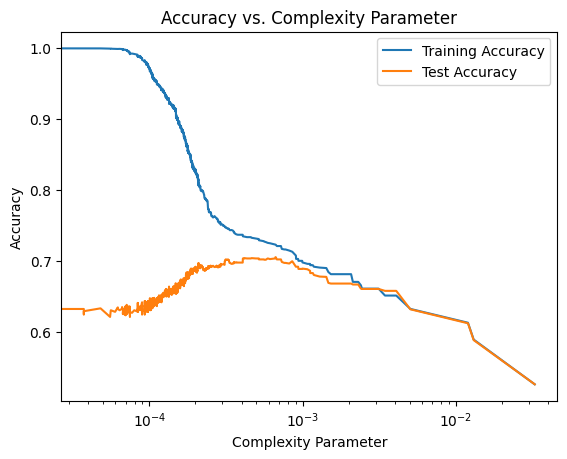

In [ ]:
path = dt.cost_complexity_pruning_path(X_train_dt, y_train_dt)
ccp_alphas = path.ccp_alphas

# Addestra l'albero decisionale con diversi valori di complessità
train_accuracy = []
test_accuracy = []
for complexity in ccp_alphas:
    clf = DecisionTreeClassifier(ccp_alpha=complexity)
    clf.fit(X_train_dt, y_train_dt)
    train_accuracy.append(clf.score(X_train_dt, y_train_dt))
    test_accuracy.append(clf.score(X_test_dt, y_test_dt))

best_idx = np.argmax(test_accuracy)
best_ccp_alpha = ccp_alphas[best_idx]
max_test_acc = np.max(test_accuracy)

print(f"Miglior ccp_alpha: {best_ccp_alpha:.6f}")
print(f"Test accuracy corrispondente: {test_accuracy[best_idx]:.4f}")

# Plotta l'accuratezza del modello in funzione del parametro di complessità
plt.plot(ccp_alphas, train_accuracy, label='Training Accuracy')
plt.plot(ccp_alphas, test_accuracy, label='Test Accuracy')
plt.xlabel('Complexity Parameter')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Complexity Parameter')
plt.xscale('log')
plt.legend()
plt.show()

###2 Creazione albero più efficente


Modello con cost complexity pruning addestrato con successo!
Profondità albero (pruned): 13
Numero di nodi (pruned): 105

Confronto:
  - Profondità: 39 → 13
  - Nodi: 5015 → 105


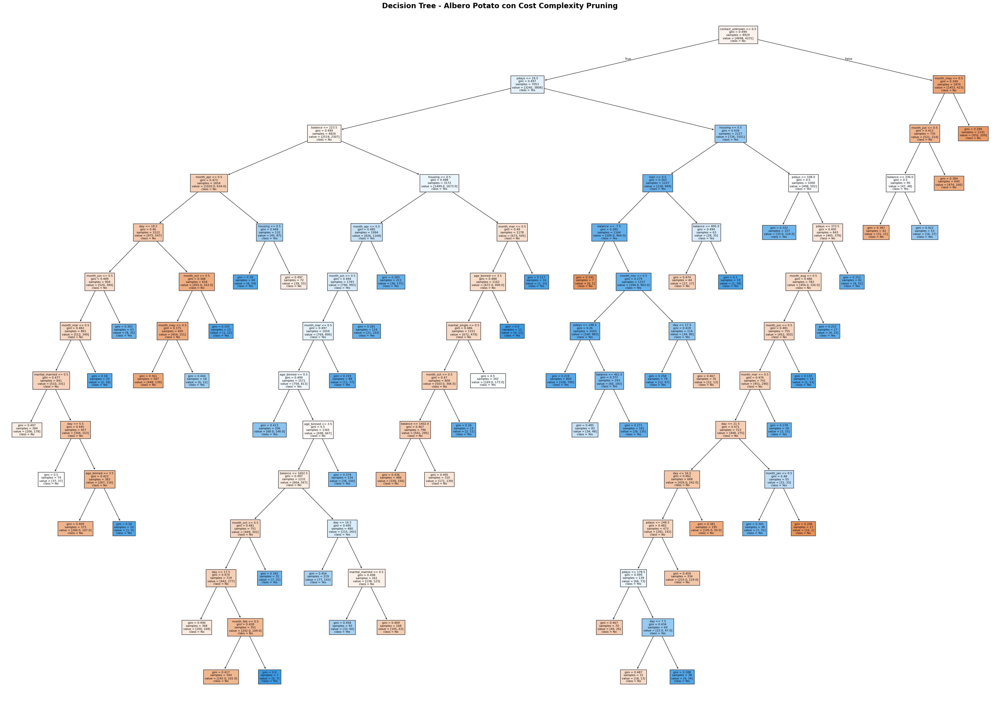

In [ ]:
dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_ccp_alpha)
dt_pruned.fit(X_train_dt, y_train_dt)

print("\nModello con cost complexity pruning addestrato con successo!")
print(f"Profondità albero (pruned): {dt_pruned.tree_.max_depth}")
print(f"Numero di nodi (pruned): {dt_pruned.tree_.node_count}")
print(f"\nConfronto:")
print(f"  - Profondità: {dt.tree_.max_depth} → {dt_pruned.tree_.max_depth}")
print(f"  - Nodi: {dt.tree_.node_count} → {dt_pruned.tree_.node_count}")

# Visualizzazione albero potato
# Dimensioni maggiori per evitare sovrapposizioni dei nodi
fig, ax = plt.subplots(figsize=(50, 35))
plot_tree(dt_pruned, feature_names=X_train_dt.columns.tolist(), class_names=['No','Yes'], filled=True, ax=ax, fontsize=8)
plt.title('Decision Tree - Albero Potato con Cost Complexity Pruning', fontsize=20, fontweight='bold')
plt.show()

### 3 Predizioni e metriche (albero potato)


In [ ]:
y_pred_dt_pruned = dt_pruned.predict(X_test_dt)
y_proba_dt_pruned = dt_pruned.predict_proba(X_test_dt)[:,1]

metrics_dt_pruned = {
    'accuracy': accuracy_score(y_test_dt, y_pred_dt_pruned),
    'precision': precision_score(y_test_dt, y_pred_dt_pruned),
    'recall': recall_score(y_test_dt, y_pred_dt_pruned),
    'f1': f1_score(y_test_dt, y_pred_dt_pruned)
}
print("METRICHE ALBERO POTATO")
print(metrics_dt_pruned)
print("\nClassification report:\n", classification_report(y_test_dt, y_pred_dt_pruned))


METRICHE ALBERO POTATO
{'accuracy': 0.7053291536050157, 'precision': 0.7564102564102564, 'recall': 0.55765595463138, 'f1': 0.6420021762785637}

Classification report:
               precision    recall  f1-score   support

           0       0.68      0.84      0.75      1175
           1       0.76      0.56      0.64      1058

    accuracy                           0.71      2233
   macro avg       0.72      0.70      0.70      2233
weighted avg       0.72      0.71      0.70      2233



### 4 Confusion Matrix (albero potato)


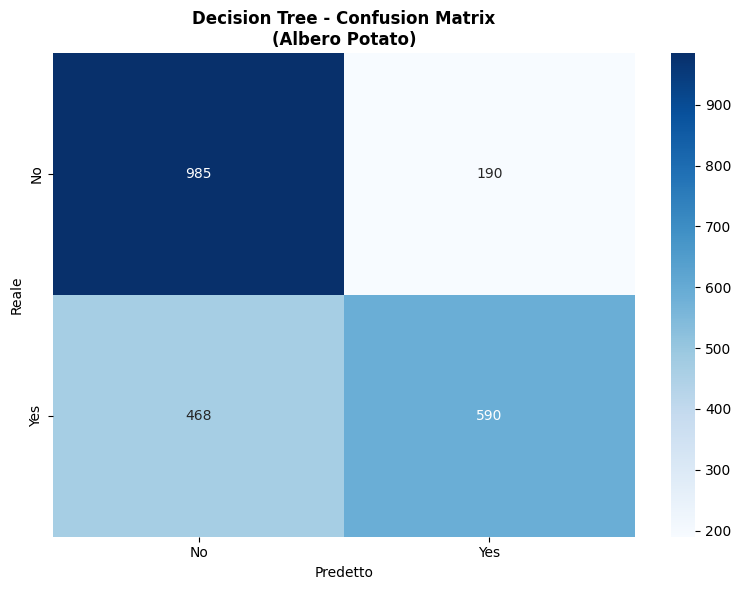

In [ ]:
cm_dt_pruned = confusion_matrix(y_test_dt, y_pred_dt_pruned)

# Confusion Matrix albero potato
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt_pruned, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.title('Decision Tree - Confusion Matrix\n(Albero Potato)', fontweight='bold')
plt.xlabel('Predetto')
plt.ylabel('Reale')
plt.tight_layout()
plt.show()

## Quarta Parte: Analisi

###1 Confronto metriche dei tre alberi

In [ ]:
# Liste valori
met_list = ['accuracy', 'precision', 'recall', 'f1']
vals_full = [metrics_dt[m] for m in met_list]
vals_d6   = [metrics_dt_depth6[m] for m in met_list]
vals_ccp  = [metrics_dt_pruned[m] for m in met_list]

# Calcolo differenza percentuale
diff_pct = [((vc - vf) / vf * 100) for vc, vf in zip(vals_ccp, vals_full)]

# Creazione DataFrame
comparison = pd.DataFrame({
    'Metrica': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Completo': vals_full,
    'Depth=6': vals_d6,
    'CCP Pruned': vals_ccp,
    '(CCP vs Full)': diff_pct
})

# Stampa Tabella Stilizzata
print("\nCONFRONTO PRESTAZIONI (METRICHE)")

headers = ['Metrica', 'Completo', 'Depth=6', 'CCP Pruned', '(CCP vs Full)']
col_widths = [12, 12, 12, 12, 15]

def print_row(values, widths):
    row_str = "| "
    for val, width in zip(values, widths):
        row_str += f"{str(val):<{width}} | "
    print(row_str)

def print_line(widths):
    line = "+-"
    for w in widths:
        line += "-" * w + "-+-"
    print(line[:-2] + "+")

# Header
print_line(col_widths)
print_row(headers, col_widths)
print_line(col_widths)

# Dati
for i in range(len(comparison)):
    row = comparison.iloc[i]
    formatted_vals = [
        row['Metrica'],
        f"{row['Completo']:.4f}",
        f"{row['Depth=6']:.4f}",
        f"{row['CCP Pruned']:.4f}",
        f"{row['(CCP vs Full)']:+.2f}%"
    ]
    print_row(formatted_vals, col_widths)
print_line(col_widths)


# Stampa Complessità Stilizzata
print("\nCOMPLESSITÀ DEGLI ALBERI (STRUTTURA)")
comp_headers = ['Metrica', 'Intero', 'Depth=6', 'CCP Pruned']
comp_widths = [15, 10, 10, 12]

print_line(comp_widths)
print_row(comp_headers, comp_widths)
print_line(comp_widths)

# Nodi
print_row(['Nodi totali', dt.tree_.node_count, dt_depth6.tree_.node_count, dt_pruned.tree_.node_count], comp_widths)
# Profondità
print_row(['Profondità', dt.tree_.max_depth, dt_depth6.tree_.max_depth, dt_pruned.tree_.max_depth], comp_widths)
print_line(comp_widths)



CONFRONTO PRESTAZIONI (METRICHE)
+--------------+--------------+--------------+--------------+-----------------+
| Metrica      | Completo     | Depth=6      | CCP Pruned   | (CCP vs Full)   | 
+--------------+--------------+--------------+--------------+-----------------+
| Accuracy     | 0.6288       | 0.6767       | 0.7053       | +12.18%         | 
| Precision    | 0.6065       | 0.6867       | 0.7564       | +24.71%         | 
| Recall       | 0.6163       | 0.5841       | 0.5577       | -9.51%          | 
| F1-Score     | 0.6113       | 0.6313       | 0.6420       | +5.01%          | 
+--------------+--------------+--------------+--------------+-----------------+

COMPLESSITÀ DEGLI ALBERI (STRUTTURA)
+-----------------+------------+------------+--------------+
| Metrica         | Intero     | Depth=6    | CCP Pruned   | 
+-----------------+------------+------------+--------------+
| Nodi totali     | 5015       | 123        | 105          | 
| Profondità      | 39         | 6   

### 2 Feature Importance (albero migliore)


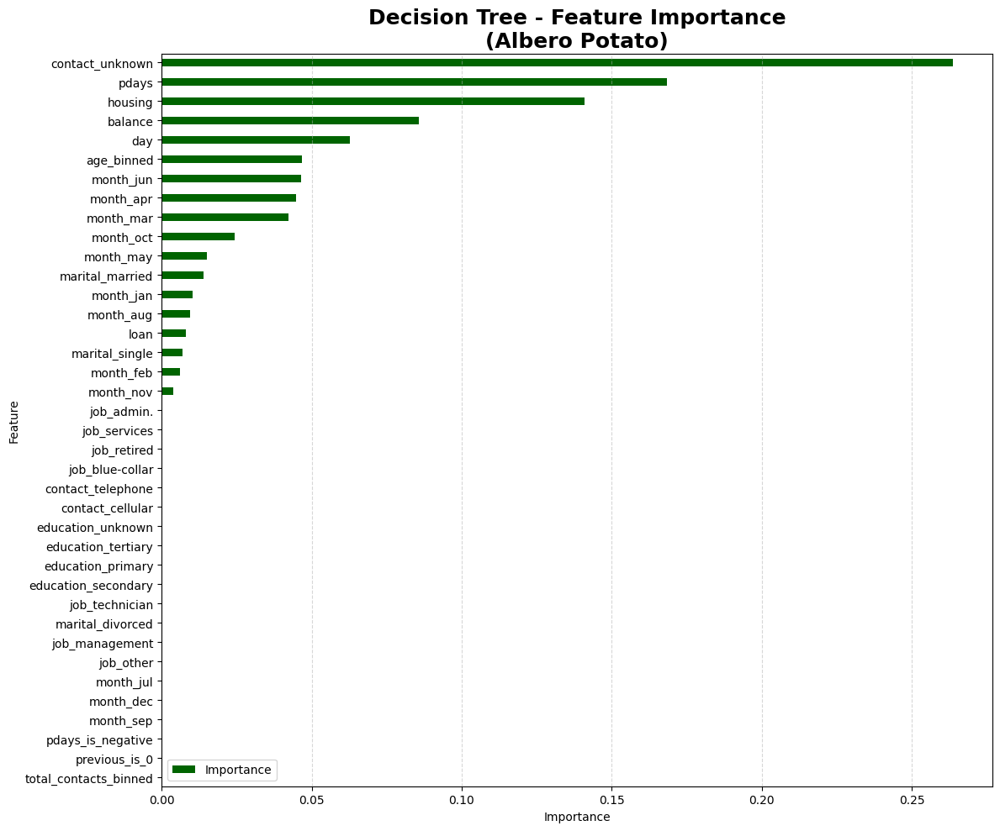

In [ ]:
feat_imp_pruned = pd.DataFrame({
    'Feature': X_train_dt.columns.tolist(),
    'Importance': dt_pruned.feature_importances_
}).sort_values('Importance', ascending=False)

# Feature Importance albero potato
plt.figure(figsize=(12, 10))

# Plot
# 'width' controlla lo spessore della barra (0.8 = spesse, quasi si toccano; 0.6 = standard)
feat_imp_pruned.plot(x='Feature', y='Importance', kind='barh',
                     color='darkgreen', width=0.4, ax=plt.gca())

# Titolo e Label
plt.title('Decision Tree - Feature Importance\n(Albero Potato)',
          fontweight='bold', fontsize=18)
plt.xlabel('Importance', fontsize=10)
plt.ylabel('Feature', fontsize=10)
plt.yticks(fontsize=10)

# Griglia leggera per aiutare la lettura
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.gca().invert_yaxis() # Mette la feature più importante in alto
plt.tight_layout()
plt.show()


# Modello 2: SVM

Le Support Vector Machines sono algoritmi di classificazione supervisionata che trovano l'iperpiano ottimale per separare le classi.

**Caratteristiche**:
- Efficaci in spazi ad alta dimensionalità
- Utilizzano i **support vectors** per definire il margine
- Diversi **kernel** (linear, RBF, polynomial) permettono classificazioni non lineari
- Il parametro **C** controlla il trade-off tra margine e errori di classificazione


## 1 Addestramento

In [ ]:
param_grid = [
    # 1. RBF (Il più probabile vincitore)
    # Riduciamo le combinazioni concentrandoci dove serve
    {'kernel': ['rbf'],
     'C': [1, 10, 25, 35, 50, 100],
     'gamma': ['scale', 0.1, 0.01],
     'class_weight': [None, 'balanced']}, # Fondamentale per la Recall

    # # 2. Linear (Come baseline veloce)
    # {'kernel': ['linear'],
    #  'C': [0.1, 1, 10],
    #  'class_weight': [None, 'balanced']},

    # # 3. Polynomial (Grado 2 è quello che funziona meglio qui)
    # {'kernel': ['poly'],
    #  'degree': [2],       # Grado 3 spesso è troppo lento/complesso
    #  'C': [1, 10],
    #  'gamma': ['scale']}
]

# Configurazione GridSearch
grid = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid,
    refit=True,     # Importante: rifitta il modello migliore alla fine
    verbose=1,
    cv=4,
    n_jobs=-1
)

print("Avvio ricerca modello migliore...")
grid.fit(X_train_svm, y_train_svm)

print(f"\nMigliori parametri trovati: {grid.best_params_}")
print(f"Migliore Accuracy in CV: {grid.best_score_:.4f}")

Avvio ricerca modello migliore...
Fitting 4 folds for each of 36 candidates, totalling 144 fits


##2 Metriche

In [ ]:
y_pred_best = grid.predict(X_test_svm)

metrics_svm_best = {
    'accuracy': accuracy_score(y_test_svm, y_pred_best),
    'precision': precision_score(y_test_svm, y_pred_best),
    'recall': recall_score(y_test_svm, y_pred_best),
    'f1': f1_score(y_test_svm, y_pred_best)
}

print(f"\nMETRICHE MIGLIOR SVM ({grid.best_params_['kernel']})")
print(metrics_svm_best)

print("\nClassification report:\n", classification_report(y_test_svm, y_pred_best))

##3 Confusion Matrix

In [ ]:
cm_svm_rbf = confusion_matrix(y_test_svm, y_pred_best)

# Confusion Matrix albero potato
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm_rbf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.title('SVM - Confusion Matrix\n(Kernel RBF)', fontweight='bold')
plt.xlabel('Predetto')
plt.ylabel('Reale')
plt.tight_layout()
plt.show()

#Dummy Model 1

In [ ]:
# Questo modello predice sempre 0 (No), perché è la classe dominante
dummy_most_frequent = DummyClassifier(strategy="most_frequent")
dummy_most_frequent.fit(X_train, y_train)
y_pred_dummy1 = dummy_most_frequent.predict(X_test)

print(f"\nDUMMY 1: Sempre 'No'")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy1):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy1):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dummy1):.4f}")


DUMMY 1: Sempre 'No'
Accuracy:  0.5262
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000


#Dummy Model 2

In [ ]:
y_pred_dummy2 = X_test['contact'].apply(lambda x: 1 if x == 'cellular' else 0)

# Ora puoi calcolare le metriche
print(f"\nDUMMY 2: Regola euristica (Cellular -> Yes)")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy2):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy2, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy2):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dummy2):.4f}")


DUMMY 2: Regola euristica (Cellular -> Yes)
Accuracy:  0.5871
Precision: 0.5423
Recall:    0.8233
F1-Score:  0.6539
